<a href="https://colab.research.google.com/github/siaelkhattat/SuperResolution/blob/main/notebooks/04_gan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import os
if not os.path.exists("/content/SuperResolution"):
    !git clone https://github.com/siaelkhattat/SuperResolution.git
%cd /content/SuperResolution
!git pull
!pip install -q -r requirements.txt
import sys; sys.path.insert(0, ".")
from src.utils.colab_setup import (mount_drive, setup_data, restore_results_from_drive,
                                   verify_repo, load_generator, sync_results_to_drive, CKPT_DIR)
mount_drive(); setup_data(); restore_results_from_drive(); verify_repo()

/content/SuperResolution
remote: Enumerating objects: 21, done.
remote: Counting objects: 100% (17/17), done.
remote: Compressing objects: 100% (10/10), done.
remote: Total 11 (delta 1), reused 11 (delta 1), pack-reused 0 (from 0)
Unpacking objects: 100% (11/11), 3.63 KiB | 1.21 MiB/s, done.
From https://github.com/siaelkhattat/SuperResolution
   73da16b..4ec66f4  main       -> origin/main
Updating 73da16b..4ec66f4
Fast-forward
 configs/{eval_yaml => eval.yaml} |    0
 configs/gan.yaml                 |   16 +
 notebooks/03_edsr_lite.ipynb     | 1672 --------------------------------------
 src/models/discriminator.py      |   16 +
 src/models/losses.py             |   16 +
 src/train/train_gan.py           |   78 ++
 6 files changed, 126 insertions(+), 1672 deletions(-)
 rename configs/{eval_yaml => eval.yaml} (100%)
 create mode 100644 configs/gan.yaml
 delete mode 100644 notebooks/03_edsr_lite.ipynb
 create mode 100644 src/models/discriminator.py
 create mode 100644 src/models/losses

In [3]:
!python -m src.train.train_gan --config configs/gan.yaml

caching train images: 100% 300/300 [00:32<00:00,  9.27it/s]
Downloading: "https://download.pytorch.org/models/vgg19-dcbb9e9d.pth" to /root/.cache/torch/hub/checkpoints/vgg19-dcbb9e9d.pth
100% 548M/548M [00:04<00:00, 130MB/s]
G params (M): 0.926723 | D params (M): 1.749825
{'epoch': 1, 'd': 0.6196, 'pix': 0.0282, 'per': 1.28, 'adv': 0.8285, 'val_psnr': nan, 'val_lpips': nan, 'minutes': 0.8}
{'epoch': 2, 'd': 0.4284, 'pix': 0.0279, 'per': 1.2351, 'adv': 1.2783, 'val_psnr': nan, 'val_lpips': nan, 'minutes': 1.6}
{'epoch': 3, 'd': 0.4438, 'pix': 0.0287, 'per': 1.232, 'adv': 1.2636, 'val_psnr': nan, 'val_lpips': nan, 'minutes': 2.5}
{'epoch': 4, 'd': 0.3995, 'pix': 0.029, 'per': 1.2237, 'adv': 1.4455, 'val_psnr': nan, 'val_lpips': nan, 'minutes': 3.4}
{'epoch': 5, 'd': 0.3761, 'pix': 0.029, 'per': 1.2071, 'adv': 1.571, 'val_psnr': nan, 'val_lpips': nan, 'minutes': 4.2}
{'epoch': 6, 'd': 0.3907, 'pix': 0.0286, 'per': 1.1914, 'adv': 1.6401, 'val_psnr': nan, 'val_lpips': nan, 'minutes': 5.1}
{

In [4]:
import sys; sys.path.insert(0, ".")
import torch, pandas as pd
from src.models.edsr_lite import EDSRLite
from src.eval.evaluate import get_datasets, evaluate_method, summarize

device = "cuda"
ck = torch.load("/content/drive/MyDrive/sr_low_cost/checkpoints/edsr_gan_best.pth", map_location=device)
G = EDSRLite(**ck["arch"]); G.load_state_dict(ck["model"])
print("best epoch:", ck["epoch"], "| val LPIPS:", round(ck["val_lpips"], 4), "| val PSNR:", round(ck["val_psnr"], 3))

datasets = get_datasets()
df = evaluate_method("edsr_gan", G, datasets, device=device)
df.to_csv("results/tables/per_image_edsr_gan.csv", index=False)
all_df = pd.concat([pd.read_csv(f"results/tables/per_image_{m}.csv")
                    for m in ["bicubic", "edsr_lite_100ep", "edsr_gan"]])
summary = summarize(all_df); summary.to_csv("results/tables/summary_all.csv", index=False)
summary

best epoch: 10 | val LPIPS: 0.2058 | val PSNR: 28.439


edsr_gan on Set5:   0%|          | 0/5 [00:00<?, ?it/s]

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
edsr_gan on Set5:  20%|██        | 1/5 [00:02<00:10,  2.62s/it]

Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth


edsr_gan on DIV2K_test: 100%|██████████| 50/50 [00:35<00:00,  1.39it/s]


,method,dataset,psnr,ssim,lpips
0,bicubic,DIV2K_test,28.4458,0.8023,0.3886
1,bicubic,Set14,26.2199,0.7263,0.4433
2,bicubic,Set5,28.6347,0.8265,0.3419
3,edsr_gan,DIV2K_test,28.9823,0.8248,0.2007
4,edsr_gan,Set14,27.2050,0.7645,0.2230
5,edsr_gan,Set5,29.9061,0.8620,0.1279
6,edsr_lite_100ep,DIV2K_test,29.5146,0.8380,0.2982
7,edsr_lite_100ep,Set14,27.7839,0.7797,0.3241
8,edsr_lite_100ep,Set5,30.9010,0.8847,0.2083


In [5]:
# Bootstrap cell first (same as always), then:
import pandas as pd
from src.models.bicubic import Bicubic
from src.eval.benchmark_speed import benchmark
from src.utils.colab_setup import load_generator, sync_results_to_drive

edsr, _ = load_generator("edsr_lite_best")
gan, ck = load_generator("edsr_gan_best")
print("GAN best epoch:", ck["epoch"], "| val LPIPS:", round(ck["val_lpips"], 4))

rows = []
for name, m in [("bicubic", Bicubic(4)), ("edsr_lite_100ep", edsr), ("edsr_gan", gan)]:
    rows.append(benchmark(name, m, device="cuda"))                     # GPU
    rows.append(benchmark(name, m, device="cpu", warmup=2, runs=10))   # CPU (slower, fewer runs)
speed = pd.concat(rows, ignore_index=True)
speed.to_csv("results/tables/speed_all.csv", index=False)
speed

GAN best epoch: 10 | val LPIPS: 0.2058


,method,device,lr_size,ms_median,ms_std,peak_mem_mb,params_m
0,bicubic,cuda,64x64,0.159,0.006,29.6,0.000
1,bicubic,cuda,256x256,2.119,0.124,52.8,0.000
2,bicubic,cpu,64x64,15.137,2.577,NaN,0.000
3,bicubic,cpu,256x256,50.859,1.101,NaN,0.000
4,edsr_lite_100ep,cuda,64x64,3.809,0.419,61.1,0.927
5,edsr_lite_100ep,cuda,256x256,49.521,0.358,556.8,0.927
6,edsr_lite_100ep,cpu,64x64,215.330,6.209,NaN,0.927
7,edsr_lite_100ep,cpu,256x256,3001.723,483.709,NaN,0.927
8,edsr_gan,cuda,64x64,5.371,1.144,57.6,0.927
9,edsr_gan,cuda,256x256,49.953,0.370,553.3,0.927


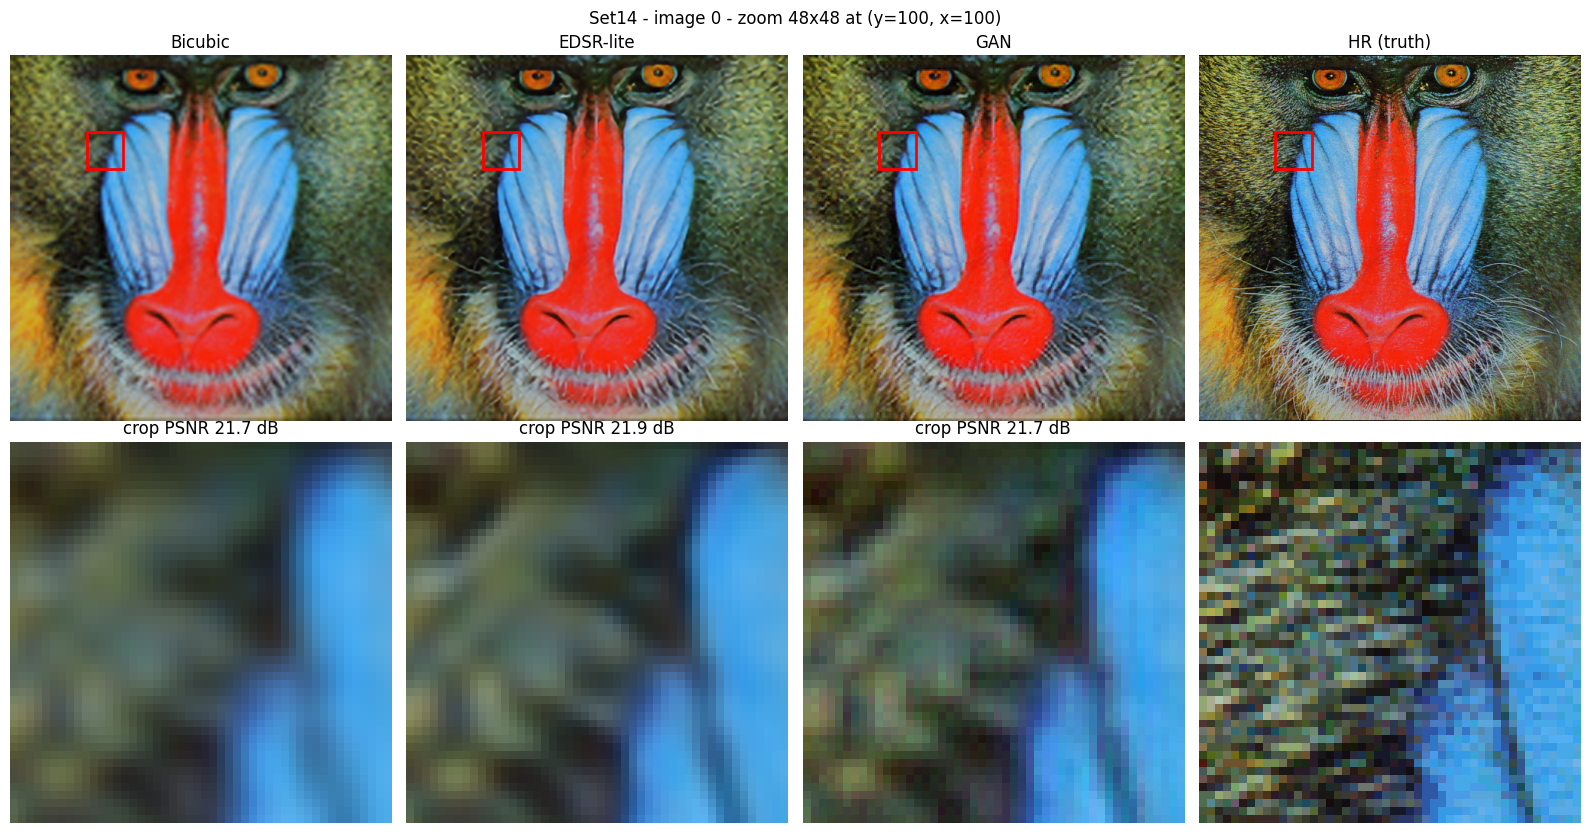

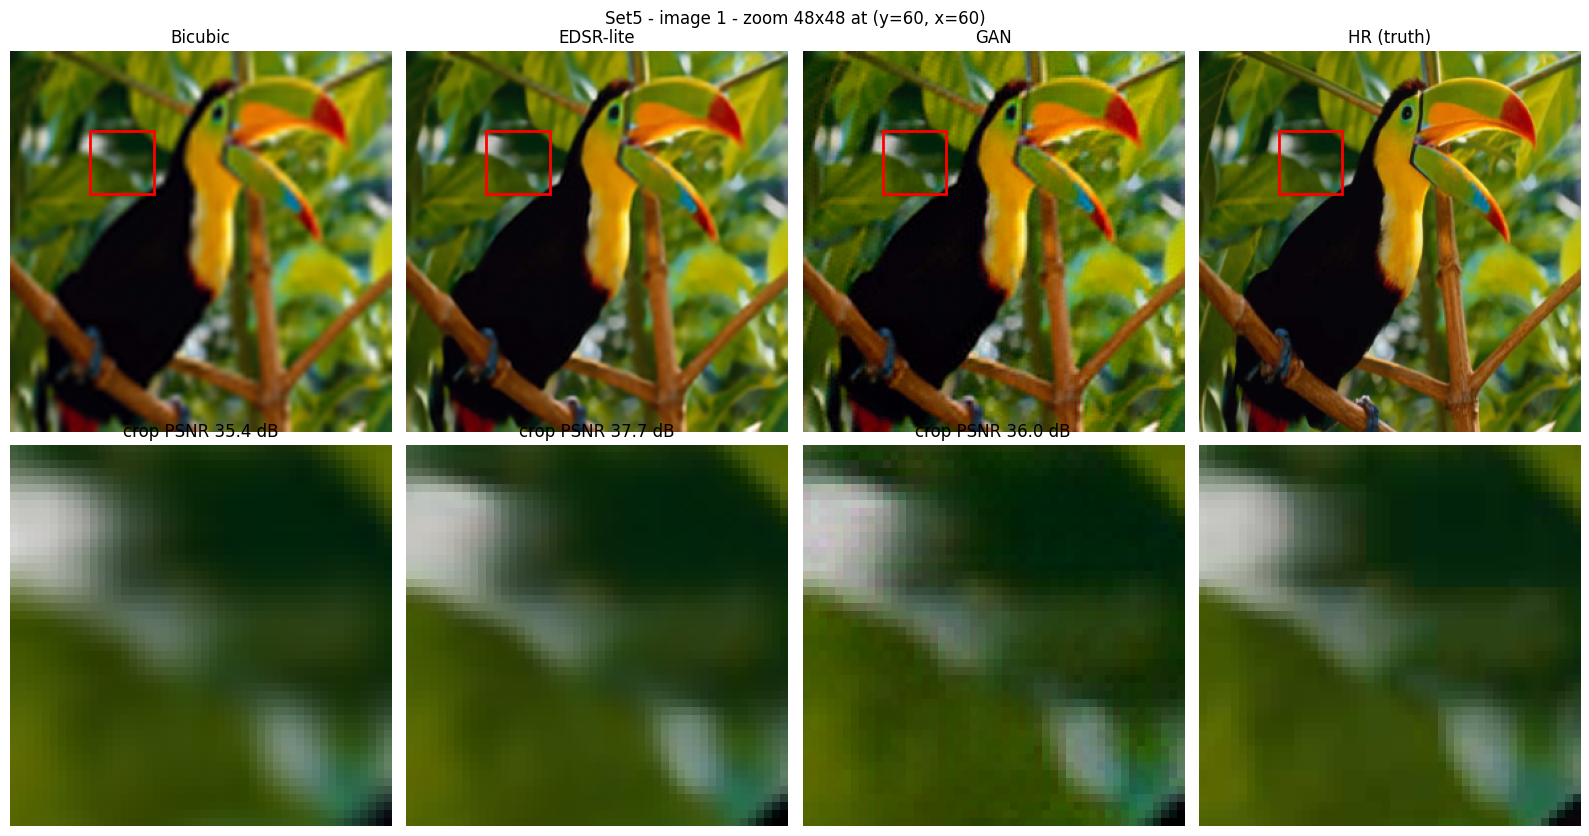

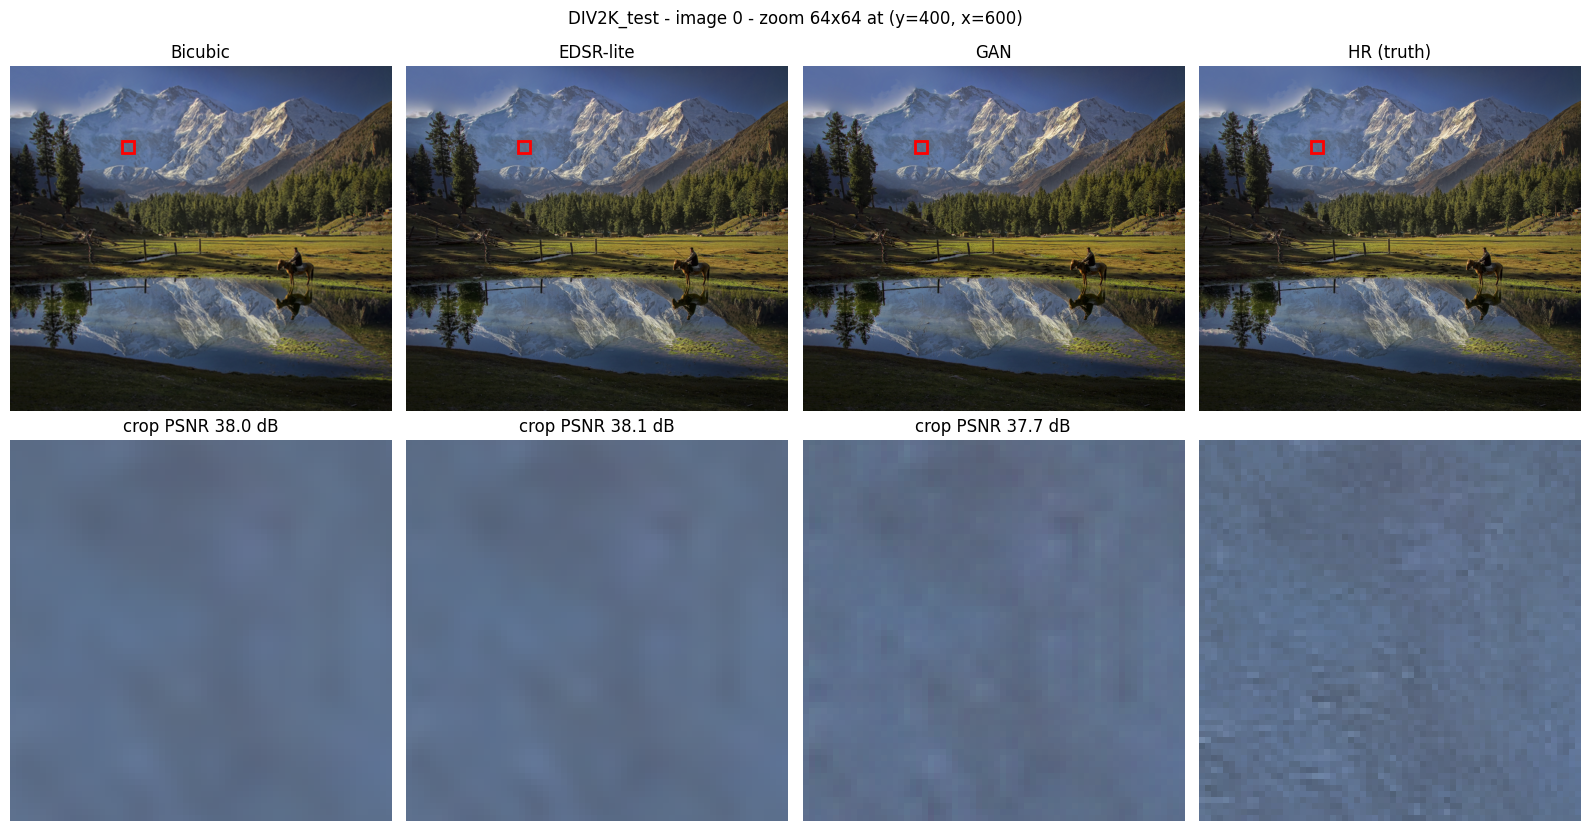

Results synced to Drive.


In [6]:
import torch, matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from pathlib import Path
from src.eval.evaluate import get_datasets, to_np
from src.eval.metrics import psnr

device = "cuda"
edsr, gan = edsr.to(device).eval(), gan.to(device).eval()
bicubic = Bicubic(4).to(device)
datasets = get_datasets()
METHODS = {"Bicubic": bicubic, "EDSR-lite": edsr, "GAN": gan}

@torch.no_grad()
def zoom_compare(dname, idx, box, save_as):
    """box = (y, x, size) in HR pixel coordinates."""
    lr, hr = datasets[dname][idx]
    y, x, s = box
    outs = {k: to_np(m(lr[None].to(device))[0]) for k, m in METHODS.items()}
    outs["HR (truth)"] = to_np(hr)
    fig, ax = plt.subplots(2, 4, figsize=(16, 8.5))
    for j, (title, im) in enumerate(outs.items()):
        ax[0, j].imshow(im); ax[0, j].set_title(title); ax[0, j].axis("off")
        ax[0, j].add_patch(Rectangle((x, y), s, s, fill=False, ec="red", lw=2))
        crop = im[y:y + s, x:x + s]
        ax[1, j].imshow(crop, interpolation="nearest"); ax[1, j].axis("off")
        if title != "HR (truth)":
            ax[1, j].set_title(f"crop PSNR {psnr(crop, outs['HR (truth)'][y:y+s, x:x+s], shave=0):.1f} dB")
    fig.suptitle(f"{dname} - image {idx} - zoom {s}x{s} at (y={y}, x={x})")
    plt.tight_layout()
    Path("results/figures").mkdir(parents=True, exist_ok=True)
    plt.savefig(f"results/figures/{save_as}.png", dpi=150); plt.show()

# Try several images and crops: the box is (y, x, size) in HR pixels
zoom_compare("Set14", 0, (100, 100, 48), "zoom_set14_0")
zoom_compare("Set5", 1, (60, 60, 48), "zoom_set5_1")
zoom_compare("DIV2K_test", 0, (400, 600, 64), "zoom_div2k_0")

sync_results_to_drive()